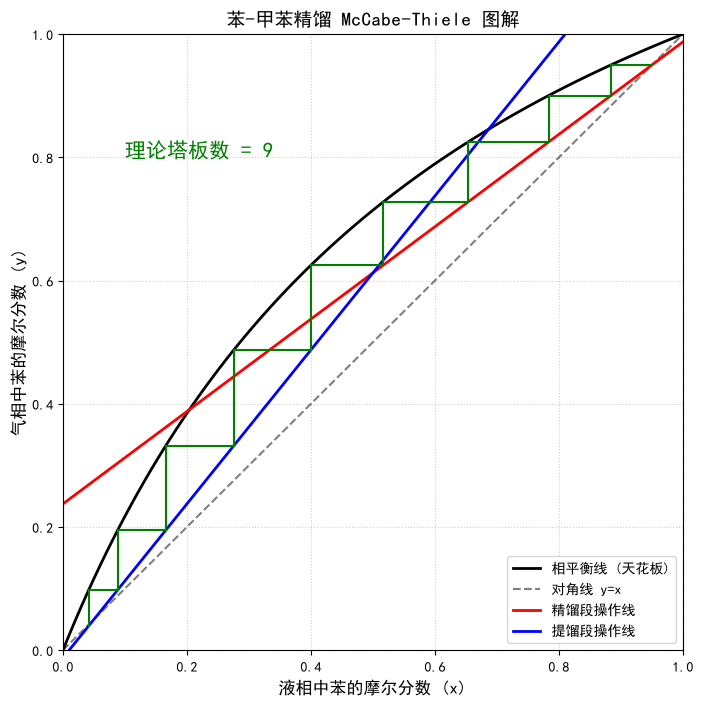

In [10]:
import numpy as np
import matplotlib.pyplot as plt


# 设定中文
plt.rcParams['font.sans-serif'] = ['SimHei']  # 设置字体为黑体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题

# ================= 1. 参数设定 =================
alpha = 2.5      # 相对挥发度（衡量分离难易程度，苯-甲苯系统在常压下约为 2.5）
xF = 0.5         # 进料中易挥发组分（苯）的摩尔分数
xD = 0.95        # 塔顶产品中苯的摩尔分数（纯度要求）
xW = 0.05        # 塔底釜液中苯的摩尔分数（残液要求）
R = 3.0          # 回流比（R越大，分离越彻底，但能耗越高；R越小，塔板数越多）

# 生成 x 轴的数据点，从 0 到 1 之间均匀取 100 个点
x = np.linspace(0, 1, 100)


# ================= 2. 相平衡曲线（天花板） =================
# 公式：y = (alpha * x) / (1 + (alpha - 1) * x)
# 逻辑：在气液平衡状态下，液相中苯的浓度 x 和气相中苯的浓度 y 的关系。
y_eq = (alpha * x) / (1 + (alpha - 1) * x)


# ================= 3. 操作线方程（地板） =================
# 精馏段操作线（上半段）：y = (R/(R+1)) * x + (xD/(R+1))
# 逻辑：基于物料平衡推导，受回流比 R 控制。
slope_rect = R / (R + 1)                 # 斜率
intercept_rect = xD / (R + 1)            # 截距
y_rect = slope_rect * x + intercept_rect # 生成精馏段直线方程

# 提馏段操作线（下半段）：基于进料点 (x_q, y_q) 和塔底点 (xW, xW) 连线
# 进料点 (x_q, y_q) 是精馏线和进料线的交点（这里假设泡点进料，进料线垂直，所以 x_q = xF）
x_q = xF 
y_q = slope_rect * x_q + intercept_rect # 算出现在精馏线在 xF 处的 y 值，这就是进料点

# 用两点式求提馏段斜率：(y2 - y1) / (x2 - x1)
slope_strip = (y_q - xW) / (x_q - xW)    
intercept_strip = xW - slope_strip * xW  # 截距，因为直线过 (xW, xW) 点
y_strip = slope_strip * x + intercept_strip


# ================= 4. 绘制基础图形 =================
fig, ax = plt.subplots(figsize=(8, 8))   # 创建 8x8 的画布

ax.plot(x, y_eq, 'k-', linewidth=2, label='相平衡线 (天花板)') # 画黑色的平衡线
ax.plot(x, x, 'k--', alpha=0.5, label='对角线 y=x')           # 画灰色的辅助对角线
ax.plot(x, y_rect, 'r-', linewidth=2, label='精馏段操作线')     # 画红色的上半段操作线
ax.plot(x, y_strip, 'b-', linewidth=2, label='提馏段操作线')    # 画蓝色的下半段操作线


# ================= 5. 画阶梯（逐板计算的核心） =================
x_curr = xD   # 当前画图的起点（x坐标），从塔顶纯度开始
y_curr = xD   # 当前画图的起点（y坐标），在对角线上
stage = 0     # 理论塔板计数器

# 循环条件：只要当前的 x 坐标还大于塔底残液要求，就继续画阶梯
while x_curr > xW:
    stage += 1  # 每画一次，算一块理论板
    
    # 【水平向左走】：寻找当前 y 下，平衡线上的 x 值
    # 因为已知 y_curr 求 x_eq，我们需要把平衡线公式反解出来：x = y / (alpha - (alpha - 1) * y)
    x_eq = y_curr / (alpha - (alpha - 1) * y_curr)
    
    # 画水平线段（从当前位置 x_curr 到 平衡线 x_eq）
    ax.plot([x_curr, x_eq], [y_curr, y_curr], 'g-', linewidth=1.5)
    
    # 【垂直向下走】：从平衡线点垂直落到操作线上，求下一块板的 y 值
    if x_eq > xF:
        # 如果还在上半段，用精馏段操作线公式
        y_next = slope_rect * x_eq + intercept_rect
    else:
        # 如果跨过了进料点，切换用提馏段操作线公式
        y_next = slope_strip * x_eq + intercept_strip
        
    # 画垂直线段（从当前平衡点 y_curr 降到 y_next）
    ax.plot([x_eq, x_eq], [y_curr, y_next], 'g-', linewidth=1.5)
    
    # 更新当前坐标，准备爬下一个台阶
    x_curr = x_eq
    y_curr = y_next

    # 安全限制（防止死循环）：如果因为参数设置问题导致算不出结果，强行跳出
    if stage > 100:
        print("警告：塔板数超过100，说明回流比R可能过小，或者参数设置有误，发生死循环。")
        break
    #死循环警告：我在代码里加了 if stage > 100: break。因为如果回流比 

    #过小，操作线会和平衡线相交（在交点处，

    #无法继续降低），导致 while 循环永远出不来，直接卡死 Jupyter。这是工艺上的“最小回流比”禁区


# ================= 6. 图形美化与显示 =================
# 在图上标注需要的理论塔板数
ax.text(0.1, 0.8, f'理论塔板数 = {stage}', fontsize=15, color='green', fontweight='bold')

ax.set_xlim(0, 1)                 # 限制 x 轴范围
ax.set_ylim(0, 1)                 # 限制 y 轴范围
ax.set_xlabel('液相中苯的摩尔分数 (x)', fontsize=12)
ax.set_ylabel('气相中苯的摩尔分数 (y)', fontsize=12)
ax.set_title('苯-甲苯精馏 McCabe-Thiele 图解', fontsize=14)
ax.legend(loc='lower right')      # 把图例放在右下角，不挡线
ax.grid(True, linestyle=':', alpha=0.6) # 加虚线网格，方便读数
plt.show()

### 死循环警告：我在代码里加了 if stage > 100: break。因为如果回流比 
>过小，操作线会和平衡线相交（在交点处，无法继续降低），导致 while 循环永远出不来，直接卡死 Jupyter。这是工艺上的“最小回流比”禁区

### R(回流比)
>当回流比是3.0是塔板数是9，回流比增大，操作线离平衡线边缘，传质推动力加大，塔板数锐减
> - 塔板数越少 说明分离越容易
> - 回流比增大，那么塔顶冷凝器、塔底蒸发器的负荷就要增大，更费钱，不划算
> - 工业界通常取 R= （1.1~2.0）Rmin,在经济和分离效果之间找平衡